# Supervised Learning & Model Engineering - Group project
# STEP 5: Three models, Optuna tuning, MLflow tracking

**Dataset:** Adult / Census Income (OpenML, `name="adult"`, `version=2`)
**Group:** Clément, Eliott Monneraie, Lucas Stefani (lead for this step: Lucas, reviewed by all)
**Course reference:** Session 3 (decision trees), Session 4 (Random Forest, gradient boosting, LightGBM), Session 5 (Pipeline, Optuna, nested cross-validation), Session 6 (business cost and threshold, rule of STEP 4)
**Code:** `src/models.py` (the three Pipelines), `src/tuning.py` (Optuna, MLflow, comparison, nested CV). Settings: `config.yaml`, sections `models` and `tuning`. Tests: `tests/test_models.py`, `tests/test_tuning.py`.

### How to read this notebook
Same labels as the previous steps: **What we see**, **What we decide**, **What could invalidate it**, **Note for STEP X**, **Limitation**.

### The rule of this step
Development set only. Every model is a **full Pipeline** (preprocessing + model, requirement 5), scored on the **same 5 folds** as STEPS 1 to 4, with the **same metrics** (requirement 4), and its threshold is chosen with the **business cost of STEP 4** (X = 5). The test set is still locked: it is used once, in STEP 6.

### How to run
The tuning itself is long (about 30 minutes on a laptop), so it lives in a script, not in this notebook:
```bash
python -m src.tuning              # tunes the 3 models, compares them, nested CV, everything in MLflow
python -m src.tuning --n-trials 5 --skip-nested   # quick check (a few minutes)
```
The script saves its tables in `reports/tuning/`; this notebook **reads** them and explains them. Only Part B (a small check) is computed here.

In [1]:
# ===================== Setup =====================
import os, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import yaml

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
from src.data import load_config, load_splits, get_cv, resolve
from src.evaluate import cross_validate_oof
from src.models import build_random_forest

warnings.filterwarnings("ignore")
cfg = load_config()
RES = resolve(cfg["tuning"]["results_dir"])          # tables written by `python -m src.tuning`
FIG_DIR = cfg["paths"]["figures_dir"]
MODELS = ["logistic", "random_forest", "lightgbm"]
LABELS = {"logistic": "Logistic regression", "random_forest": "Random Forest", "lightgbm": "LightGBM"}
COLORS = {"logistic": "#8da0cb", "random_forest": "#66c2a5", "lightgbm": "#fc8d62"}
sns.set_theme(style="whitegrid")

def savefig(name: str) -> None:
    path = os.path.join(FIG_DIR, f"{name}.png")
    plt.tight_layout(); plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved: {path}")

X_dev, _, y_dev, _ = load_splits(cfg)                 # the test set is not used in STEP 5
cv = get_cv(cfg)
print(f"Development set: {len(y_dev):,} rows, prevalence {y_dev.mean():.2%}")
print("Results read from:", RES)

Development set: 39,032 rows, prevalence 23.94%
Results read from: /tmp/claude-0/repo/reports/tuning


---
# Part A - What this step does

## A.1 The three models (requirement 4)
The course goes from a linear model to trees, then to ensembles of trees. We follow the same path:

| Model | Session | What it adds | Inputs (STEP 2) |
|---|---|---|---|
| **Logistic regression** (L2) | S1, S2 | The reference: one coefficient per input, easy to read | one-hot, scaled, age and hours bands |
| **Random Forest** | S3, S4 | Non-linear shapes and interactions learned automatically; **averaging** many deep trees reduces their variance | one-hot or ordinal codes (Part B), no bands |
| **LightGBM** | S4 | **Boosting**: small trees added one after the other, each correcting the previous errors; native categorical columns | ordinal codes read as categories, no bands |

Trees get no age / hours bands: they find their own cut points (decision 13). Every model is one Pipeline built by `src/models.py`, so the same raw row goes in and a probability comes out.

## A.2 What Optuna is, in plain words
A **hyperparameter** is a setting chosen **before** training (the strength C of the penalty, the number of trees, their depth...). The model does not learn it from the data, so we have to choose it, and the choice changes the score.

- **Grid search** (Session 5) tries every combination of a fixed list: with 7 LightGBM settings and 5 values each, that is 78,125 combinations, impossible.
- **Optuna** works in rounds called **trials**. At each trial it proposes one set of values, we score it with our 5-fold cross-validation, and it **uses the scores of the previous trials** to propose better values next time (the TPE sampler learns which regions of the search space give good scores). After 10 random trials to explore, it concentrates on the promising regions.
- **Pruning:** after each fold, a trial whose running score is below the median of the previous trials at the same fold is **stopped early**. A hopeless setting does not use 5 folds of computing time.

**What Optuna maximises:** the **mean PR-AUC over the 5 folds** (our main metric, decision 1). Not the business cost: the cost depends on the threshold, and the threshold is chosen **after** the model, on its out-of-fold predictions (STEP 4 rule).

## A.3 Why the best score of the tuning is optimistic, and what we do about it
After 60 trials we keep the best one. But part of its score is **luck on these 5 folds**: among 60 settings with almost the same true quality, the best-looking one is often the one that was lucky. It is the same trap as the threshold of STEP 4 (an in-sample backtest), now on hyperparameters. Session 5 gives two answers, and we use both:
1. **Nested cross-validation** (Part F, now): for each of the 5 folds, Optuna runs on the 4 other folds only (with an inner 3-fold CV), and the chosen model is scored on the 5th fold, which played no part in the choice. This measures the score of the **whole procedure** "tune, then fit".
2. **The untouched test set** (STEP 6): one single evaluation of the final model.

---
# Part B - A question before tuning: how should categories reach the Random Forest?
scikit-learn's Random Forest has no categorical mode. Two options:
- **ordinal codes** (`occupation` = 0, 1, 2...): one column per variable, but the tree reads an order that does not exist (occupation 3 < occupation 7). It can still isolate a category, with several cuts;
- **one-hot**: one yes/no column per category, no fake order, more columns.

We compare both with **default** settings, on the same 5 folds (paired comparison), for two leaf sizes.

In [2]:
# ===================== B.1 Ordinal vs one-hot for the Random Forest =====================
rows, folds = [], {}
for leaf in [1, 10]:
    for enc in ["ordinal", "onehot"]:
        per_fold, _ = cross_validate_oof(build_random_forest(cfg, encoding=enc, n_estimators=300,
                                                             min_samples_leaf=leaf), X_dev, y_dev, cv)
        folds[(enc, leaf)] = per_fold["pr_auc"].to_numpy()
    d = folds[("onehot", leaf)] - folds[("ordinal", leaf)]
    rows.append({"min_samples_leaf": leaf, "PR-AUC ordinal": folds[("ordinal", leaf)].mean(),
                 "PR-AUC one-hot": folds[("onehot", leaf)].mean(), "one-hot - ordinal (mean)": d.mean(),
                 "per fold": ", ".join(f"{v:+.4f}" for v in d),
                 "folds where one-hot wins": f"{int((d > 0).sum())}/5"})
display(pd.DataFrame(rows).set_index("min_samples_leaf").style.format(
    {"PR-AUC ordinal": "{:.4f}", "PR-AUC one-hot": "{:.4f}", "one-hot - ordinal (mean)": "{:+.4f}"}))

,PR-AUC ordinal,PR-AUC one-hot,one-hot - ordinal (mean),per fold,folds where one-hot wins
min_samples_leaf,,,,,
1,0.6841,0.6770,-0.0071,"-0.0065, -0.0051, -0.0102, -0.0070, -0.0069",0/5
10,0.7435,0.7447,+0.0012,"+0.0011, +0.0000, +0.0020, +0.0010, +0.0020",5/5


**What we see.**
- With fully grown trees (`min_samples_leaf = 1`), the **ordinal codes win on every fold** (about -0.007 for one-hot).
- With bigger leaves (`min_samples_leaf = 10`), **one-hot wins** on every fold, but only by about +0.001.
- In both cases the gap is small (below 0.01), and **its sign depends on the other hyperparameters**.

**What we decide (decision 33).** We do not choose by hand: the encoding becomes **one more hyperparameter** of the Random Forest (`encoding: [onehot, ordinal]` in `config.yaml`), and Optuna chooses it together with the depth and the leaf size. Part C shows what it picked.

**Why this matters.** A Random Forest that reads ordinal codes sees a fake order between categories (Session 3: a split is "value <= threshold"). It is a real modelling question, not a detail, and we want the data to answer it on the same folds as everything else.

---
# Part C - The tuning: what Optuna found
## C.1 Search spaces (from `config.yaml`)

In [3]:
# ===================== C.1 Search spaces =====================
rows = []
for model in MODELS:
    for name, spec in cfg["tuning"]["search_spaces"][model].items():
        rng = spec["choices"] if spec["type"] == "categorical" else f"{spec['low']} to {spec['high']}"
        rows.append({"model": LABELS[model], "hyperparameter": name, "type": spec["type"], "range": str(rng),
                     "log scale": spec.get("log", False)})
display(pd.DataFrame(rows).set_index(["model", "hyperparameter"]))
print("Trials per model:", cfg["tuning"]["n_trials"])

type                  range  \
model               hyperparameter                                          
Logistic regression C                        float         0.001 to 100.0   
Random Forest       encoding           categorical  ['onehot', 'ordinal']   
                    n_estimators               int             100 to 500   
                    max_depth                  int                4 to 30   
                    min_samples_leaf           int                1 to 50   
                    max_features             float            0.05 to 0.7   
LightGBM            n_estimators               int            100 to 2000   
                    learning_rate            float            0.01 to 0.2   
                    num_leaves                 int               8 to 128   
                    min_child_samples          int               5 to 200   
                    reg_lambda               float         0.001 to 100.0   
                    subsample                float             0.5 to 1.0   
                    colsample_bytree         float             0.2 to 1.0   

                                       log scale  
model               hyperparameter                
Logistic regression C                       True  
Random Forest       encoding               False  
                    n_estimators           False  
                    max_depth              False  
                    min_samples_leaf        True  
                    max_features           False  
LightGBM            n_estimators           False  
                    learning_rate           True  
                    num_leaves              True  
                    min_child_samples       True  
                    reg_lambda              True  
                    subsample              False  
                    colsample_bytree       False

Trials per model: {'logistic': 20, 'random_forest': 40, 'lightgbm': 60}


**Why these ranges.**
- **Logistic regression:** only `C` = 1 / lambda (Session 2), from very strong (0.001) to almost no penalty (100), on a log scale because it spans five orders of magnitude.
- **Random Forest:** the size of the forest (`n_estimators`), how deep each tree may grow (`max_depth`) and how small a leaf may be (`min_samples_leaf`): these are the bias / variance controls of Sessions 3 and 4. `max_features` is the share of columns tried at each split: it makes the trees different from each other, which is what makes averaging work. Plus the encoding of Part B.
- **LightGBM:** `n_estimators` x `learning_rate` (many small steps or few big ones), `num_leaves` and `min_child_samples` (size of each tree), `reg_lambda` (an L2 penalty on the leaf values, the idea of Session 2 applied to trees), `subsample` and `colsample_bytree` (each tree sees a random share of rows and columns, against overfitting).

Figure saved: reports/figures/17_optuna_history.png


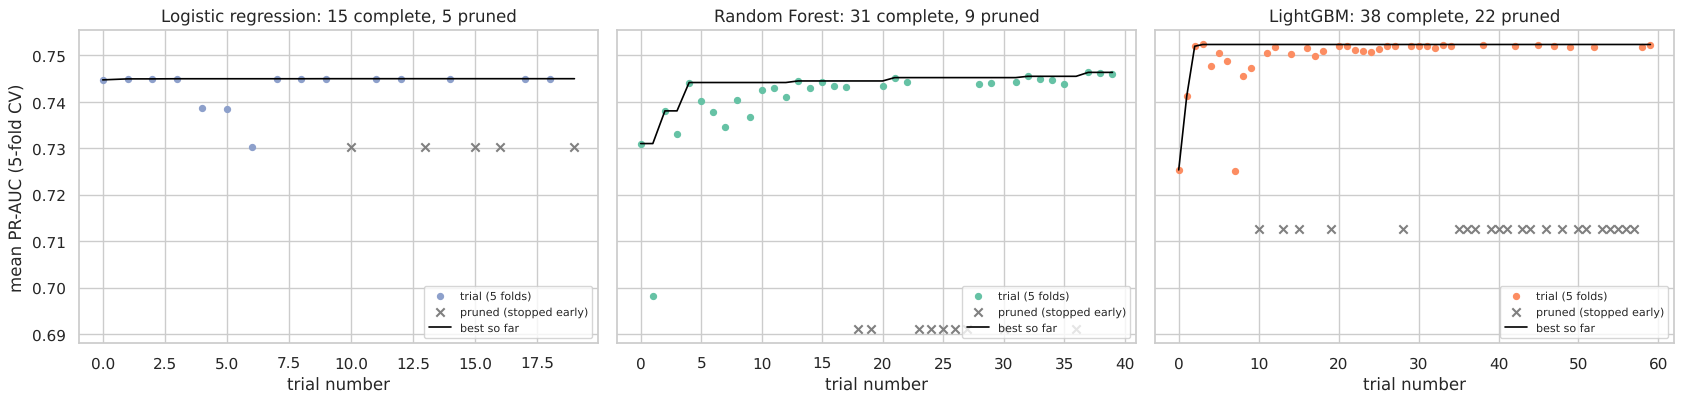

Logistic regression  best PR-AUC 0.7449  params: C=3.47
Random Forest        best PR-AUC 0.7463  params: encoding=onehot, n_estimators=350, max_depth=20, min_samples_leaf=7, max_features=0.2693
LightGBM             best PR-AUC 0.7523  params: n_estimators=350, learning_rate=0.02399, num_leaves=21, min_child_samples=25, reg_lambda=8.431, subsample=0.5998, colsample_bytree=0.6114


In [4]:
# ===================== C.2 Optimisation history =====================
trials = {m: pd.read_csv(RES / f"trials_{m}.csv", index_col="trial") for m in MODELS}
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2), sharey=True)
for ax, m in zip(axes, MODELS):
    t = trials[m]
    done, pruned = t[t["state"] == "COMPLETE"], t[t["state"] == "PRUNED"]
    ax.scatter(done.index, done["pr_auc"], s=18, color=COLORS[m], label="trial (5 folds)")
    ax.scatter(pruned.index, [t["pr_auc"].min()] * len(pruned), marker="x", color="grey",
               label="pruned (stopped early)")
    ax.plot(done["pr_auc"].cummax().reindex(t.index).ffill(), color="black", lw=1.2, label="best so far")
    ax.set_title(f"{LABELS[m]}: {len(done)} complete, {len(pruned)} pruned")
    ax.set_xlabel("trial number"); ax.legend(fontsize=8, loc="lower right")
axes[0].set_ylabel("mean PR-AUC (5-fold CV)")
savefig("17_optuna_history")
plt.show()

best = yaml.safe_load(open(RES / "best_params.yaml"))
for m in MODELS:
    print(f"{LABELS[m]:20s} best PR-AUC {trials[m]['pr_auc'].max():.4f}  params: "
          + ", ".join(f"{k}={v:.4g}" if isinstance(v, float) else f"{k}={v}" for k, v in best[m].items()))

**What we see.**
- **Logistic regression** (20 trials, 5 pruned): best `C` = 3.5, PR-AUC **0.7449**, the same as the default `C` = 1 of STEP 3 (0.745). 14 of the 20 trials are within 0.002 of the best: with 39,000 rows and about 50 columns, the penalty barely matters. The baseline was already well set.
- **Random Forest** (40 trials, 9 pruned): best PR-AUC **0.7463**, with one-hot encoding, 350 trees, depth 20, at least 7 people per leaf and 27% of the columns tried at each split. Moderate leaves and a small `max_features` make the trees different from each other, which is what makes the average work (Session 4). The best one-hot trial (0.7463) and the best ordinal trial (0.7454) are very close, as Part B suggested.
- **LightGBM** (60 trials, 22 pruned): best PR-AUC **0.7523**, with 350 rounds at a learning rate of 0.024, small trees (21 leaves), a strong L2 penalty (`reg_lambda` = 8.4) and each tree seeing 60% of the rows and 61% of the columns. The pruner stopped more than a third of the trials early, which saved about a third of the computing time.
- **None of the best values sits on the edge of its search range.** It was not the case in our first run (LightGBM wanted the maximum number of trees, the maximum `reg_lambda` and the minimum `colsample_bytree`), so we widened those three ranges and ran the tuning again. A best value on an edge means the true best may be outside the range.

Figure saved: reports/figures/18_lightgbm_hyperparameters.png


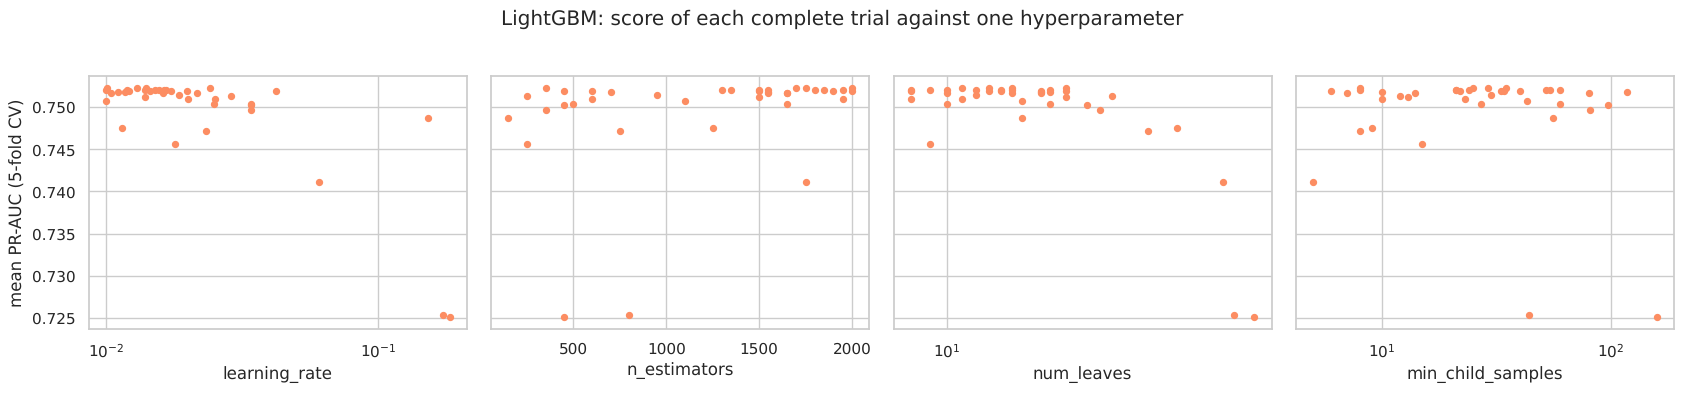

Correlation between PR-AUC and learning_rate x n_estimators (total amount of learning): -0.57


In [5]:
# ===================== C.3 LightGBM: which hyperparameters matter? =====================
t = trials["lightgbm"][trials["lightgbm"]["state"] == "COMPLETE"]
params = ["learning_rate", "n_estimators", "num_leaves", "min_child_samples"]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8), sharey=True)
for ax, p in zip(axes, params):
    ax.scatter(t[p], t["pr_auc"], s=18, color=COLORS["lightgbm"])
    if p in ("learning_rate", "num_leaves", "min_child_samples"):
        ax.set_xscale("log")
    ax.set_xlabel(p)
axes[0].set_ylabel("mean PR-AUC (5-fold CV)")
fig.suptitle("LightGBM: score of each complete trial against one hyperparameter", y=1.03)
savefig("18_lightgbm_hyperparameters")
plt.show()
t = t.assign(total_learning=t["learning_rate"] * t["n_estimators"])
print("Correlation between PR-AUC and learning_rate x n_estimators (total amount of learning):",
      round(t["pr_auc"].corr(np.log(t["total_learning"])), 2))

**What we see.**
- The **worst trials** (PR-AUC 0.725 to 0.741) all combine **big trees** (56 to 68 leaves) with a **high learning rate** (0.06 to 0.18): each new tree corrects too much and the model learns the noise of the training folds (overfitting, Session 4). This is what the negative correlation (-0.57) between the score and the total amount of learning (`learning_rate` x `n_estimators`) shows.
- The **good trials** all use **small trees** (8 to 28 leaves) and a **small learning rate** (0.01 to 0.04), with many rounds to compensate: "many small steps" rather than "a few big ones".
- The top is a **plateau**: 29 of the 38 complete trials are within 0.002 of the best, with very different settings (350 or 2,000 rounds, `reg_lambda` from 0.001 to 97). The chosen setting is not a fragile, lucky point, and the exact values do not matter much as long as the trees stay small and the learning slow.

---
# Part D - The three tuned models, same metrics (requirement 4)
For each model, the best hyperparameters are refitted on the same 5 folds, which gives out-of-fold probabilities. Then the **rule of STEP 4** is applied: the threshold that minimises the business cost (X = 5) on those predictions.

In [6]:
# ===================== D.1 Comparison table =====================
comp = pd.read_csv(RES / "comparison.csv", index_col="model").rename(index=LABELS)
show = comp[["pr_auc_mean", "pr_auc_std", "roc_auc_mean", "log_loss_mean", "threshold", "recall", "precision",
             "calls", "missed", "cost", "fold_cost_std", "cost_honest"]]
display(show.style.format({"pr_auc_mean": "{:.4f}", "pr_auc_std": "{:.4f}", "roc_auc_mean": "{:.4f}",
                           "log_loss_mean": "{:.4f}", "threshold": "{:.2f}", "recall": "{:.1%}",
                           "precision": "{:.1%}", "calls": "{:,.0f}", "missed": "{:,.0f}", "cost": "{:,.0f}",
                           "fold_cost_std": "{:,.0f}", "cost_honest": "{:,.0f}"}))
print("Reference STEP 4 (default logistic regression, t = 0.17): PR-AUC 0.745, cost 12,681")

paired = pd.read_csv(RES / "paired_vs_logistic.csv", index_col="model").rename(index=LABELS)
print("\nPaired differences with the tuned logistic regression (same folds):")
display(paired[["pr_auc_diff_mean", "pr_auc_diff_std", "folds_better_pr_auc", "pr_auc_diff_per_fold",
                "cost_diff_mean", "cost_diff_std", "folds_lower_cost", "cost_diff_per_fold"]]
        .style.format({"pr_auc_diff_mean": "{:+.4f}", "pr_auc_diff_std": "{:.4f}",
                       "cost_diff_mean": "{:+.1f}", "cost_diff_std": "{:.1f}"}))

,pr_auc_mean,pr_auc_std,roc_auc_mean,log_loss_mean,threshold,recall,precision,calls,missed,cost,fold_cost_std,cost_honest
model,,,,,,,,,,,,
Logistic regression,0.7449,0.0116,0.9011,0.3281,0.17,90.5%,50.7%,"16,679",890,"12,674",77,"12,748"
Random Forest,0.7463,0.0074,0.9028,0.3261,0.18,91.0%,50.3%,"16,909",841,"12,610",59,"12,679"
LightGBM,0.7523,0.0084,0.9051,0.3225,0.15,91.6%,50.3%,"17,035",781,"12,376",58,"12,490"


Reference STEP 4 (default logistic regression, t = 0.17): PR-AUC 0.745, cost 12,681

Paired differences with the tuned logistic regression (same folds):


,pr_auc_diff_mean,pr_auc_diff_std,folds_better_pr_auc,pr_auc_diff_per_fold,cost_diff_mean,cost_diff_std,folds_lower_cost,cost_diff_per_fold
model,,,,,,,,
Random Forest,+0.0014,0.0045,4/5,"+0.0043, +0.0024, +0.0002, +0.0056, -0.0058",-12.8,47.2,3/5,"-42, +16, -18, -70, +50"
LightGBM,+0.0074,0.0037,5/5,"+0.0099, +0.0076, +0.0057, +0.0116, +0.0020",-59.6,34.8,5/5,"-86, -39, -55, -102, -16"


Figure saved: reports/figures/19_model_comparison.png


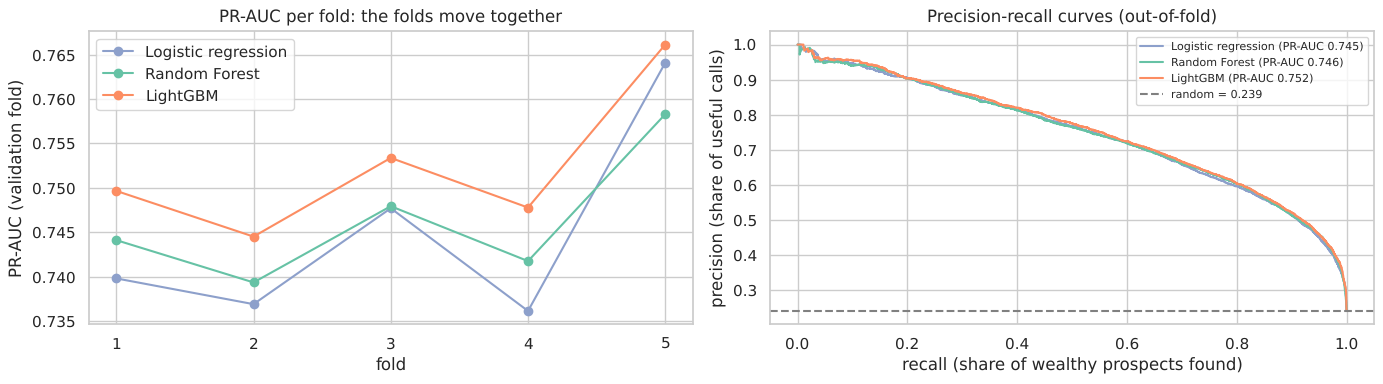

In [7]:
# ===================== D.2 Per fold, every model =====================
per_fold = {m: pd.read_csv(RES / f"per_fold_{m}.csv", index_col="fold") for m in MODELS}
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for m in MODELS:
    axes[0].plot(per_fold[m].index, per_fold[m]["pr_auc"], marker="o", color=COLORS[m], label=LABELS[m])
axes[0].set(xlabel="fold", ylabel="PR-AUC (validation fold)", title="PR-AUC per fold: the folds move together")
axes[0].set_xticks(range(1, 6)); axes[0].legend()
oof = pd.read_csv(RES / "oof_predictions.csv", index_col=0)
from sklearn.metrics import precision_recall_curve
for m in MODELS:
    p, r, _ = precision_recall_curve(oof["target"], oof[m])
    axes[1].plot(r, p, color=COLORS[m], label=f"{LABELS[m]} (PR-AUC {comp.loc[LABELS[m], 'pr_auc_mean']:.3f})")
axes[1].axhline(y_dev.mean(), ls="--", color="grey", label=f"random = {y_dev.mean():.3f}")
axes[1].set(xlabel="recall (share of wealthy prospects found)", ylabel="precision (share of useful calls)",
            title="Precision-recall curves (out-of-fold)")
axes[1].legend(fontsize=8)
savefig("19_model_comparison")
plt.show()

**What we see.**
- **Same metrics for the three models** (requirement 4): PR-AUC from 0.745 to 0.752, ROC-AUC from 0.901 to 0.905, log-loss from 0.328 to 0.323. At their own best threshold for X = 5 (0.15 to 0.18), the three find about 91% of the wealthy prospects with about 50% useful calls.
- **LightGBM beats the tuned logistic regression on all 5 folds**: +0.0074 PR-AUC on average (between +0.002 and +0.012 per fold) and a **lower business cost on all 5 folds** (-60 per fold on average, about -2.4%). On the development set it finds 109 more wealthy prospects (8,564 vs 8,455) for 356 more calls.
- **The Random Forest is not clearly better than the logistic regression**: +0.0014 PR-AUC (4 folds out of 5), and the cost goes up or down depending on the fold (3 folds out of 5).
- The curves on the left move together: fold 5 is easy and fold 2 is hard **for every model**. This is why we compare the models fold by fold (paired): the spread between folds (about 0.01) is larger than the gaps between models, but the gaps themselves are very regular for LightGBM.
- **Honest cost** (threshold chosen without the fold, STEP 4 method): 12,748 for the logistic regression, 12,679 for the Random Forest, **12,490 for LightGBM**.

**What each step bought us (requirement 4).**
1. **Logistic regression, tuned:** nothing more than STEP 3. Our feature engineering (age and hours bands, capital indicators) had already given the linear model the main non-linear shapes.
2. **Random Forest:** almost nothing. Averaging deep trees learns the non-linearities and interactions by itself, but our data are not much more than what the bands already describe.
3. **LightGBM:** a small but **consistent** gain, +0.007 PR-AUC and -2.4% business cost on every fold. Boosting corrects the errors left by the previous trees and finds the few interactions that the linear model misses.

**What we decide (decision 35).** **LightGBM** is our candidate final model, with its tuned hyperparameters and its own threshold (0.15 at X = 5, chosen on its out-of-fold predictions). STEP 6 recomputes it and evaluates it **once** on the test set.

**What could invalidate it.** A gain of this size could disappear on the test set. If LightGBM does not beat the logistic regression there, we would keep the logistic regression: same performance, simpler and fully readable.

**Limitation.** The gain of the trees is small because we removed the exact capital amounts (decision 7): STEP 1 showed they are worth +0.08 PR-AUC for a tree model. STEP 6 reports the "amounts" reference to show what this choice costs.

---
# Part E - LightGBM and class imbalance (open point of STEP 4)
STEP 4 kept **threshold tuning only** for the logistic regression and left one check for the trees: does reweighting the positive class (Session 6, `scale_pos_weight`) help LightGBM? We use `is_unbalance=True`, which weighs the positive class by n_negative / n_positive **computed on the training folds**, the same idea as `scale_pos_weight` without hard-coding 3.2. Same rule as STEP 4: each version gets its own best threshold, and the costs are compared fold by fold.

In [8]:
# ===================== E.1 Threshold only vs is_unbalance =====================
lg = pd.read_csv(RES / "lightgbm_imbalance.csv", index_col="model")
display(lg[["pr_auc_mean", "log_loss_mean", "threshold", "recall", "precision", "cost", "fold_cost_mean",
            "cost_diff_vs_threshold_only_per_fold"]]
        .style.format({"pr_auc_mean": "{:.4f}", "log_loss_mean": "{:.4f}", "threshold": "{:.2f}",
                       "recall": "{:.1%}", "precision": "{:.1%}", "cost": "{:,.0f}", "fold_cost_mean": "{:,.0f}"}))

,pr_auc_mean,log_loss_mean,threshold,recall,precision,cost,fold_cost_mean,cost_diff_vs_threshold_only_per_fold
model,,,,,,,,
lightgbm_threshold_only,0.7523,0.3225,0.15,91.6%,50.3%,"12,376","2,475",-
lightgbm_is_unbalance,0.7523,0.3909,0.35,92.2%,49.8%,"12,343","2,469","+18, +10, -22, -41, +2"


**What we see.**
- **Same ranking:** PR-AUC 0.7523 with or without reweighting.
- **Same cost:** the per-fold differences are +18, +10, -22, -41, +2, so reweighting wins on 2 folds and loses on 3. There is no regular gain, unlike the logistic regression where class weights won 5 folds out of 5 by a very small margin.
- **Distorted probabilities:** the log-loss goes from 0.323 to 0.391, and the best threshold moves from 0.15 to 0.35. Reweighting inflates the probabilities, and the threshold simply moves to compensate, exactly as in STEP 4.

**What we decide (decision 36).** **Threshold only** for LightGBM too. Reweighting does not lower the business cost and it damages the probabilities that STEP 7 (calibration) and STEP 9 (fairness) need.

---
# Part F - Is the tuned score optimistic? Nested cross-validation (requirement 6)
For each outer fold k (the same 5 folds as always):
1. Optuna runs on the **other 4 folds only**, with an inner 3-fold CV (smaller budget: 10 to 20 trials);
2. the best setting is refitted on those 4 folds;
3. it is scored on fold k, which played **no part** in the choice.

The mean of the 5 outer scores estimates what the procedure "tune with Optuna, then fit" gives on new data. The difference with the tuning score of Part C is the **optimism of the selection**.

In [9]:
# ===================== F.1 Nested CV =====================
nested = pd.read_csv(RES / "nested_summary.csv", index_col="model").rename(index=LABELS)
display(nested.style.format("{:.4f}"))
for m in MODELS:
    t = pd.read_csv(RES / f"nested_{m}.csv", index_col="outer_fold")
    print(f"\n{LABELS[m]}: outer PR-AUC per fold", ", ".join(f"{v:.4f}" for v in t["outer_pr_auc"]))
    print("  hyperparameters chosen in each outer fold:")
    for k, p in t["best_params"].items():
        print(f"   fold {k}: {p}")

,tuning_cv_pr_auc,nested_pr_auc_mean,nested_pr_auc_std,optimism
model,,,,
Logistic regression,0.7449,0.7449,0.0117,0.0000
Random Forest,0.7463,0.7443,0.0093,0.0020
LightGBM,0.7523,0.7521,0.0085,0.0002



Logistic regression: outer PR-AUC per fold 0.7397, 0.7368, 0.7477, 0.7362, 0.7642
  hyperparameters chosen in each outer fold:
   fold 1: {'C': 0.9846738873614566}
   fold 2: {'C': 1.0129197956845732}
   fold 3: {'C': 1.0129197956845732}
   fold 4: {'C': 0.9846738873614566}
   fold 5: {'C': 0.9846738873614566}

Random Forest: outer PR-AUC per fold 0.7416, 0.7343, 0.7461, 0.7406, 0.7592
  hyperparameters chosen in each outer fold:
   fold 1: {'encoding': 'ordinal', 'n_estimators': 200, 'max_depth': 17, 'min_samples_leaf': 9, 'max_features': 0.18106704306550228}
   fold 2: {'encoding': 'ordinal', 'n_estimators': 150, 'max_depth': 17, 'min_samples_leaf': 8, 'max_features': 0.08019276826799852}
   fold 3: {'encoding': 'ordinal', 'n_estimators': 150, 'max_depth': 17, 'min_samples_leaf': 8, 'max_features': 0.08019276826799852}
   fold 4: {'encoding': 'ordinal', 'n_estimators': 150, 'max_depth': 17, 'min_samples_leaf': 8, 'max_features': 0.08019276826799852}
   fold 5: {'encoding': 'ordinal'

**What we see.**
- **The nested scores are almost identical to the tuning scores:** 0.7449 vs 0.7449 (logistic regression), 0.7443 vs 0.7463 (Random Forest), 0.7521 vs 0.7523 (LightGBM). The optimism of the selection is at most **0.002** PR-AUC.
- **The ranking holds:** LightGBM is the best model in the nested CV too, and it is the best on every outer fold.
- In each outer fold Optuna picks somewhat different hyperparameters (printed above), but they give almost the same score: the top of the search space is flat (Part C.3).

**Why the optimism is so small here.** It grows with the number of settings tried and shrinks with the size of the validation data. Our folds hold about 7,800 people each and the best trials are all close to each other, so the "lucky winner" effect is tiny.

**What we decide (decision 37).** The scores of Part D are reliable estimates of the tuning procedure (requirement 6). The final confirmation is the single evaluation on the test set in STEP 6.

---
# Part G - MLflow: every trial is logged (requirement 7)
`python -m src.tuning` writes in the local `mlruns/` folder (not committed):
- one **parent run** per model, `step5_tune_<model>`: search space, number of trials, best trial, table of all trials (artifact);
- one **child run per Optuna trial**, completed or pruned: its hyperparameters, PR-AUC / ROC-AUC / log-loss / precision / recall / F1 of each fold and their mean and std, the trial state;
- one run `step5_final_<model>` per tuned model: the STEP 4 operating point (threshold, business cost);
- one run `step5_nested_<model>`: the 5 outer scores of the nested CV.

To browse them: `mlflow ui`, then http://127.0.0.1:5000, experiment `adult-income` (click on a parent run to unfold its trials).

In [10]:
# ===================== G.1 What is in MLflow =====================
import mlflow
from src.tracking import setup_mlflow
setup_mlflow(cfg)
runs = mlflow.search_runs(experiment_names=[cfg["tracking"]["experiment_name"]], filter_string="tags.step = '5'")
runs["kind"] = np.where(runs["tags.mlflow.parentRunId"].notna(), "trial (child run)", runs["tags.role"])
display(runs.groupby(["tags.model", "kind"]).size().unstack(fill_value=0))
if "tags.optuna_state" in runs:
    print("Trial states:", runs["tags.optuna_state"].value_counts().to_dict())

kind,nested_cv,optuna_study,trial (child run),tuned_model
tags.model,,,,
lightgbm,1,1,60,1
logistic,1,1,20,1
random_forest,1,1,40,1


Trial states: {'complete': 84, 'pruned': 36}


**What we see.** Every trial of every model is in MLflow (requirement 7), the pruned ones included, each with its hyperparameters and its metrics fold by fold. Each model also has its parent run (the study), its final run (threshold, business cost) and its nested-CV run. Nothing has to be re-run to answer a question such as "what did trial 17 of LightGBM give?".

---
# Part H - Decisions log for STEP 5 (copied into DECISIONS.md)
| # | Decision | Why | What could invalidate it | Where |
|---|---|---|---|---|
| 33 | Random Forest: the categorical encoding (one-hot or ordinal) is a hyperparameter chosen by Optuna; LightGBM: native categorical columns (pandas 'category') | sklearn's RF reads ordinal codes as ordered numbers; the better encoding depends on the other settings (Part B); LightGBM groups categories natively | - | `src/models.py`, `config.yaml` |
| 34 | Optuna (TPE sampler, seed 42, 10 random start trials, median pruner after 2 folds) maximises the mean PR-AUC over the 5 folds; 20 / 40 / 60 trials; search ranges widened until no best value sits on an edge | PR-AUC is the main metric (decision 1); the cost depends on the threshold, chosen afterwards (decision 28); pruning saves about a third of the time | A best value on the edge of a range | `src/tuning.py`, `config.yaml` (`tuning`) |
| 35 | Candidate final model: **LightGBM** (PR-AUC 0.752 vs 0.745, cost -2.4%, better on 5/5 folds), threshold 0.15 at X = 5 | Consistent paired gain over the tuned logistic regression; the Random Forest brings no regular gain | A paired comparison on new data that reverses the gain; the choice is then frozen before the test set (decision 39: the test set measures, it never chooses) | `reports/tuning/`, notebook 05 |
| 36 | LightGBM: threshold only, no `is_unbalance` / `scale_pos_weight` | Same PR-AUC, no regular cost gain (2 folds better, 3 worse), log-loss 0.32 -> 0.39 | - | notebook 05, Part E |
| 37 | Nested CV (5 outer folds, Optuna on 3 inner folds) confirms the scores: optimism at most 0.002 PR-AUC, same ranking | Requirement 6: the reported score must not be optimistic (S5) | - | `nested_cv`, notebook 05, Part F |
| 38 | Every Optuna trial (complete or pruned) is an MLflow child run under one parent run per model, plus a final run and a nested-CV run per model | Requirement 7: every run, parameters, metrics and artifacts, for all three models | - | `src/tuning.py`, `src/tracking.py` |